## Trabajo Práctico 3 - Probabilidad multidimensional

7. **(Para entregar)** Simular una variable aleatoria $X = (X_1, X_2)$ que sigue una distribución binormal con parámetros $\mu_1 = 2.3$,  $\mu_2 = 1.5$, $\sigma_1 = 1.2$, $\sigma_2 = 0.5$ y correlación $\rho = 0.7$. Repetir la simulación 1000 veces. Calcular la fracción de eventos caen en la elipse $1\sigma$ y comparar con la probabilidad contenida dentro de dicha región. Graficar 10 de los datos simulados junto a la elipse 1σ.

Nota: un punto $(x_1, x_2)$ pertenece a la elipse $r\sigma$ si la forma cuadrática asociada $q(x_1, x_2) ≤ r$.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
from scipy.stats import multivariate_normal
import danatools
from numpy import linalg

In [ ]:
# Parámetros
mu1 = 2.3
mu2 = 1.5
sigma1 = 1.2
sigma2 = 0.5
corr = 0.7

mu = np.array([mu1, mu2]) # armo un vector para la media de X
covariance_X = danatools.covariance_matrix_2d(sigma1, sigma2, corr)
covariance_X



array([[1.44, 0.42],
       [0.42, 0.25]])

In [ ]:
# Simulación de la variable aleatora X=(X1,X2)
n_sims = 1000
X = multivariate_normal.rvs(mu, covariance_X, size=n_sims, random_state=42)

### Elipse $1\sigma$

Se graficarán 10 puntos de los simulados junto con la elipse $1\sigma$. El gráfico muestra que un 40% de los datos caen dentro de la región de interés. Sin embargo, esto varía cuando cambio la semilla. Usando tan pocos datos (mucho error estadístico) no puedo estimar la probabilidad de que caiga en esa región.

Para calcular la cantidad de eventos que caen en la región $1\sigma$ voy a calcular la forma cuadrática Q y luego contar cuantos eventos cumplen con la condición Q < 1. Por último, la fracción de eventos que caen en la región $1\sigma$ será n = N_1sigma / n_sims.

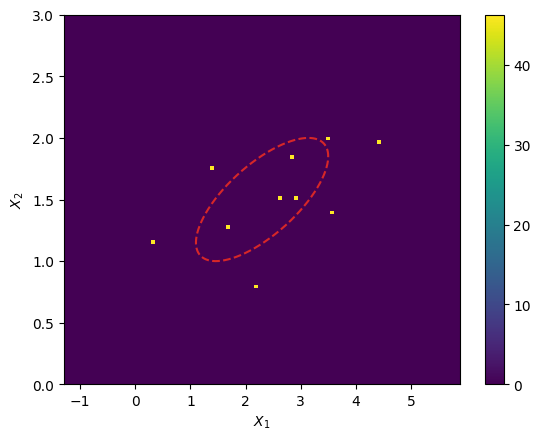

In [ ]:
fig, ax = plt.subplots()
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")

limit1 = [mu1-3*sigma1, mu1+3*sigma1]
limit2 = [mu2-3*sigma2, mu2+3*sigma2]
counts, xedges, yedges, im = ax.hist2d(X[:10,0], X[:10,1], range=[limit1, limit2], bins=100, density=True, cmap=cm.viridis)
clb = plt.colorbar(im)

ax.plot(*danatools.get_ellipse(mu, covariance_X, nsigma=1), color='tab:red', ls='--')


In [ ]:
# Forma Cuadrática Q

Hessian_matrix = linalg.inv(covariance_X)
v = X - mu
Q = np.sum((v@Hessian_matrix)*v, axis=1)

# Contar cuantos eventos caen dentro de la elipse 1sigma
N_1sigma = len(Q[Q <= 1])

# Fracción de eventos que caen en la elipse 1sigma
n = N_1sigma / n_sims

print('Fracción de eventos que caen en la elipse 1 sigma:', n)




Fracción de eventos que caen en la elipse 1 sigma: 0.4


In [ ]:
# Probabilidad teórica (CDF)

from scipy.stats import chi2

# Grados de libertad
df = 2  # porque estamos en 2D

# Probabilidades
p_1sigma = chi2.cdf(1, df)  # Para 1 sigma
print('Probabilidad para 1σ:', p_1sigma)



Probabilidad para 1σ: 0.3934693402873665


La fracción de eventos simulados que caen dentro de la elipse $1\sigma$ dió aproximadamente igual a la probabilidad calculada con la CDF que corresponde a una $\chi^2_2$.